In [1]:
import pandas as pd
import numpy as np
import joblib, os

X = pd.read_csv("../data/processed/X_features.csv", index_col=0)
y = pd.read_csv("../data/processed/y_labels.csv", index_col=0)["Disease"]

print(X.shape, y.shape)

(304, 131) (304,)


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": BernoulliNB(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    scores = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "F1 (macro)": scores["test_f1_macro"].mean(),
        "Accuracy std": scores["test_accuracy"].std(),
    })

pd.DataFrame(results).sort_values("F1 (macro)", ascending=False).round(3)

,Model,Accuracy,F1 (macro),Accuracy std
0,Logistic Regression,1.000,1.000,0.000
1,Random Forest,1.000,1.000,0.000
3,Naive Bayes,0.977,0.966,0.020
2,Decision Tree,0.618,0.532,0.057


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

best_model = RandomForestClassifier(n_estimators=200, random_state=42)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 1.0
                               precision    recall  f1-score   support

                         AIDS       1.00      1.00      1.00         1
                         Acne       1.00      1.00      1.00         1
          Alcoholic hepatitis       1.00      1.00      1.00         2
                      Allergy       1.00      1.00      1.00         1
                    Arthritis       1.00      1.00      1.00         2
             Bronchial Asthma       1.00      1.00      1.00         2
         Cervical spondylosis       1.00      1.00      1.00         2
                  Chicken pox       1.00      1.00      1.00         2
          Chronic cholestasis       1.00      1.00      1.00         2
                  Common Cold       1.00      1.00      1.00         2
                       Dengue       1.00      1.00      1.00         3
                     Diabetes       1.00      1.00      1.00         2
                Drug Reaction       1.00      1.00      1

In [12]:
def top3(symptoms):
    row = pd.DataFrame([np.zeros(len(X.columns))], columns=X.columns)
    for s in symptoms:
        if s in row.columns:
            row[s] = 1
    probs = best_model.predict_proba(row)[0]
    top = np.argsort(probs)[::-1][:3]
    return [(best_model.classes_[i], float(round(probs[i] * 100, 1))) for i in top]

top3(["chest_pain", "breathlessness", "sweating", "vomiting"])

[('Heart attack', 98.5), ('Malaria', 0.5), ('GERD', 0.5)]

[('Heart attack', np.float64(94.5)),
 ('Gastroenteritis', np.float64(1.5)),
 ('Bronchial Asthma', np.float64(1.5))]

In [6]:
os.makedirs("../models", exist_ok=True)
best_model.fit(X, y)   # retrain on all data for the final app
joblib.dump(best_model, "../models/disease_model.pkl")
joblib.dump(list(X.columns), "../models/symptom_list.pkl")
print("Model saved!")

Model saved!


In [7]:
rng = np.random.default_rng(42)

def keep_k_symptoms(X_part, k):
    X_new = X_part.copy()
    for idx in X_new.index:
        present = X_new.columns[X_new.loc[idx] == 1]
        if len(present) > k:
            drop = rng.choice(present, size=len(present) - k, replace=False)
            X_new.loc[idx, drop] = 0
    return X_new

rows = []
for name in ["Random Forest", "Logistic Regression", "Naive Bayes"]:
    model = models[name].fit(X_train, y_train)
    for k in [1, 2, 3, 4, 5]:
        Xk = keep_k_symptoms(X_test, k)
        rows.append({"Symptoms given": k, "Model": name,
                     "Accuracy": accuracy_score(y_test, model.predict(Xk))})

robust = pd.DataFrame(rows).pivot(index="Symptoms given", columns="Model", values="Accuracy").round(3)
robust

Model,Logistic Regression,Naive Bayes,Random Forest
Symptoms given,,,
1,0.289,0.303,0.342
2,0.553,0.526,0.592
3,0.737,0.671,0.684
4,0.803,0.789,0.803
5,0.895,0.868,0.921


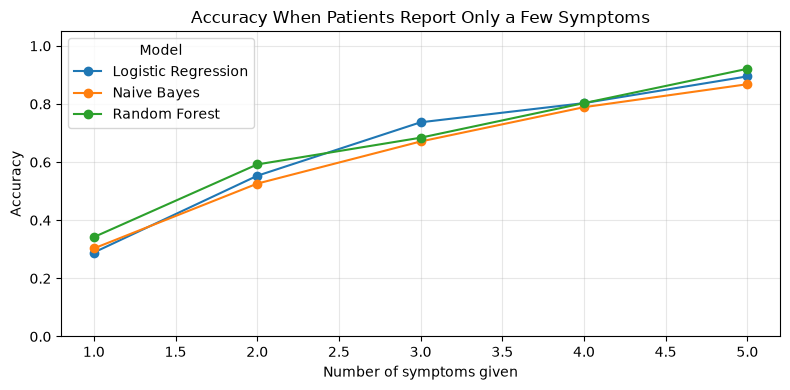

In [8]:
import matplotlib.pyplot as plt

robust.plot(marker="o", figsize=(8, 4))
plt.title("Accuracy When Patients Report Only a Few Symptoms")
plt.xlabel("Number of symptoms given")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../docs/figures/robustness_test.png", dpi=150)
plt.show()